In [23]:
import numpy as np
from sentence_transformers import SentenceTransformer

sentences = [
    "Eu ainda acho que isso é uma péssima ideia",
    "Se você está com medo, pode voltar sozinho",
    "Shh… estamos quase lá",
    "Vocês ouviram isso?",
    "Provavelmente é só o vento",
    "Isso não é vento!",
    "A porta está logo ali",
    "Você tem certeza que é aqui?",
    "Foi o que eu li",
    "Então abre",
    "Devagar",
    "Essa porta vai denunciar a gente",
    "Meu Deus...",
    "O que é aquilo?",
    "Não faz barulho",
    "Ele tem três cabeças",
    "Isso é normal aqui?",
    "Eu realmente espero que não",
    "Ele está acordando",
    "Fecha a porta agora!",
    "Empurra!",
    "Corre!",
    "Não olha pra trás!",
    "Eu disse que era uma péssima ideia",
    "Calma, continua correndo",
    "Vira à esquerda",
    "Espera, alguém está vindo",
    "Se escondam",
    "Fiquem quietos",
    "Ora, ora… o que temos aqui?",
    "Boa noite…",
    "Alunos fora da cama",
    "Nós estávamos apenas…",
    "Silêncio, venham comigo",
    "Estamos encrencados",
    "Eu te disse",
    "Estou profundamente decepcionada",
    "Vocês não fazem ideia do perigo em que estavam",
    "Não há justificativa",
    "Pontos serão retirados",
    "E vocês terão detenção",
    "Mas professora, aquilo estava guardando alguma coisa",
    "Guardando alguma coisa?",
    "Debaixo dele tinha um alçapão",
    "Um alçapão?",
    "Eu vi também",
    "Então não era só um cachorro",
    "O que será que tem lá embaixo?",
    "Não faço ideia, mas deve ser importante",
    "Ninguém colocaria uma criatura daquelas por acaso",
    "Você acha que é algo proibido?",
    "Ou algo muito valioso",
    "Se for, alguém está tentando proteger",
    "Ou esconder",
    "A gente não devia estar falando disso",
    "Mas agora eu não consigo parar de pensar",
    "Nem eu",
    "Isso explica muita coisa",
    "Ou complica ainda mais",
    "De qualquer forma, precisamos tomar cuidado",
    "E ficar longe daquele corredor",
    "Pelo menos por enquanto",
    "Concordo",
    "Mas eu ainda quero descobrir o que tem lá"
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20087.28it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(64, 768)
[[-0.01059808  0.03678442 -0.02576697 ... -0.04533979 -0.02788712
  -0.00101658]
 [ 0.03475586  0.03438161 -0.02443053 ... -0.03142483 -0.05379376
   0.03350024]
 [ 0.01617075  0.00307208 -0.02864313 ... -0.03200499 -0.05736565
   0.03245775]
 ...
 [ 0.00298264  0.03086798 -0.04235849 ... -0.03255799 -0.03343431
   0.0273628 ]
 [-0.00274825  0.03545773 -0.02544981 ... -0.04498141 -0.05016806
   0.03494795]
 [ 0.00114833  0.02640715 -0.03915269 ... -0.04470447 -0.02825578
   0.01557826]]


In [24]:
S = model.encode(sentences_e5, normalize_embeddings=False)

scores = np.dot(S, S.T)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i:
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.88246906 0.         0.         ... 0.         0.         0.        ]
 [0.84224117 0.84610409 0.         ... 0.         0.         0.        ]
 ...
 [0.86806571 0.85651362 0.88520676 ... 0.         0.         0.        ]
 [0.80149889 0.80084038 0.84466898 ... 0.82911849 0.         0.        ]
 [0.8911826  0.86860633 0.8425076  ... 0.88196015 0.79489285 0.        ]]


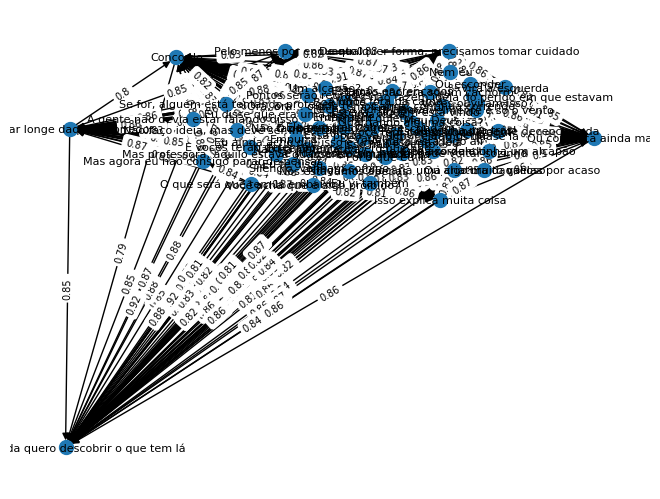

In [25]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

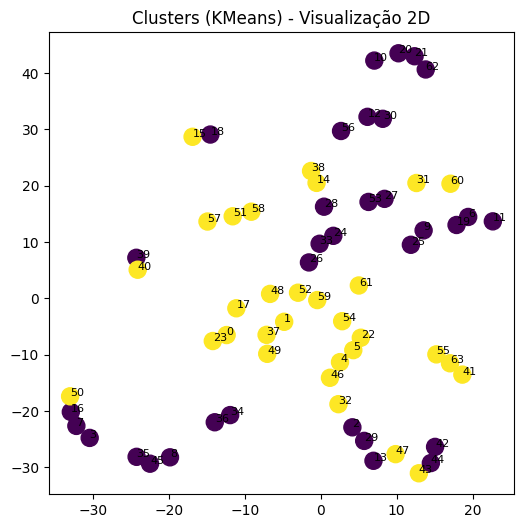

In [45]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=2, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

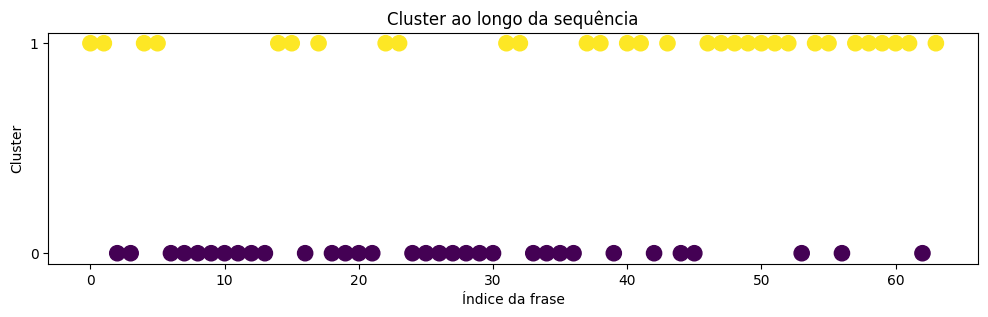

In [46]:
plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,1])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

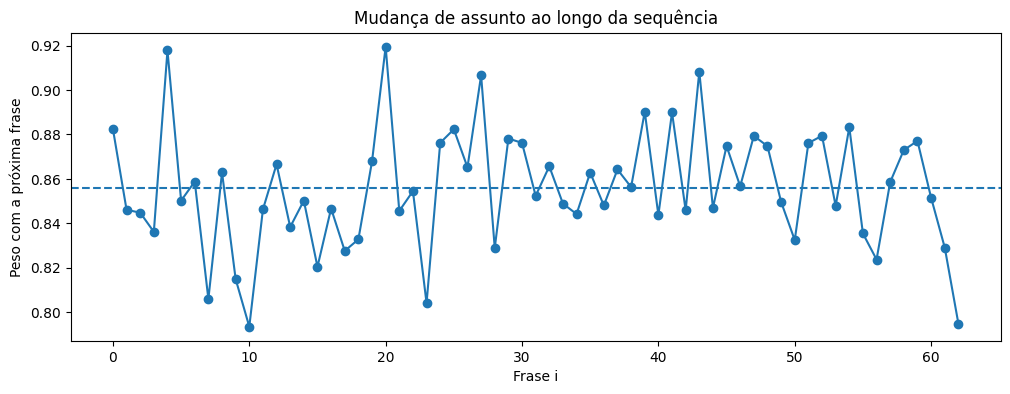

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)

weights = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(len(S_norm) - 1)
])

plt.figure(figsize=(12, 4))
plt.plot(weights, marker='o')
plt.axhline(np.mean(weights), linestyle='--')
plt.xlabel("Frase i")
plt.ylabel("Peso com a próxima frase")
plt.title("Mudança de assunto ao longo da sequência")
plt.show()

In [48]:
def cosine(a, b):
    return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]

k = 3  

pivot_scores = []

for i in range(k, len(S_norm) - k):
    prev_ctx = S_norm[i-k:i].mean(axis=0)
    next_ctx = S_norm[i+1:i+k+1].mean(axis=0)
    score = 1 - cosine(prev_ctx, next_ctx)
    pivot_scores.append((i, score))

pivot_scores.sort(key=lambda x: x[1], reverse=True)

print("Frases mais relevantes para mudança de rumo:")
for i, score in pivot_scores[:5]:
    print(f"\nÍndice {i} | score = {score:.4f}")
    print(sentences[i])

Frases mais relevantes para mudança de rumo:

Índice 18 | score = 0.0967
Ele está acordando

Índice 19 | score = 0.0832
Fecha a porta agora!

Índice 22 | score = 0.0779
Não olha pra trás!

Índice 13 | score = 0.0726
O que é aquilo?

Índice 41 | score = 0.0705
Mas professora, aquilo estava guardando alguma coisa
